<p style="text-align:center"><img src="../../../../Images/Banner/04_spatial_stat/04_10_spatial_capstone.png" alt="Spatial Statistics Capstone" width="100%"></p>

# Drug Overdose Mortality - Rate vs Model Rate, and Geographically Weighted Models



This is Part 10 (Capstone) of the spatial-statistics module. It is one public-health geography study run end to end: exploratory maps and diagnostics, then a head-to-head comparison of four **geographically weighted** predictors of county drug-overdose mortality.

Two outcomes, from the same counties (2014–2018):

| Column | Meaning |
|---|---|
| `Rate` | Observed overdose mortality rate (deaths per 100,000) |
| `Model_Rate` | Hierarchical Bayesian (INLA) model-based rate estimate |

`Model_Rate` shrinks unstable raw rates toward a spatial prior. Comparing models on both outcomes asks whether a predictor that fits the noisy observed rate also recovers the smoothed surface — and where the two diverge.

**Models compared** (same covariates, same coordinates, same spatial-block cross-validation):

| Model | Class | Role |
|---|---|---|
| GWR | `geolattice.spatial_statistics.gwmodel.linear.GWR` | Geographically weighted OLS (local linear) |
| GW Random Forest | `GWRandomForest` | Local + global tree ensemble |
| GW XGBoost | `GWXGBoost` | Local + global gradient boosting |
| GNNWR | `GNNWR` | Neural-network weighted local regression (PyTorch) |

Data: `Data/00_shared/data_spatial_stat/drug_overdose_all_2014_2018_updated_no_NA.csv` (2,150 counties with complete covariates). Methods come from `gwmodel.linear`, `gwmodel.ensemble`, `gwmodel.deep`, plus `esda` / `weights` for exploratory spatial structure.

## Overview

> Across contiguous-US counties with complete 2014–2018 overdose records, which geographically weighted model best predicts overdose mortality — and does the ranking change when the target is the raw rate versus the INLA model-based rate?

| Step | What we do |
|------|------------|
| Data | Join the CSV to `US_COUNTY.shp` polygons on FIPS, audit CRS |
| EDA | Map `Rate` and `Model_Rate`, scatter them, summarise by `FLAG` / urban–rural |
| Structure | Correlations, VIF, Moran's I of both outcomes |
| Models | Fit GWR, GW RF, GW XGBoost, and GNNWR to each outcome |
| Fair score | Spatial-block (quadrant) cross-validation — not random folds |
| Local insight | GWR coefficient maps; GW-RF local feature importance |
| Report | Comparison table, residual maps, decision log |

**Caveats.** County rates are ecological: they do not identify individual risk. `Model_Rate` is already a spatial smooth, so models that also smooth spatially can look artificially good against it. In-sample \(R^2\) for tree ensembles is optimistic; trust the spatial-block CV.

## API overview

```
- SpatialData
- Queen, W, Moran, moran_scatter
- OLS
- GWR
- GWRandomForest, GWXGBoost
- GNNWR
```

## Setup

**Installation.** This notebook needs installation option 3 (core, spatial analysis and spatial statistics): `pip install "geolattice[statistics]"`. See "Installation options" in the GeoLattice README.

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from sklearn.preprocessing import StandardScaler
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
for candidate in [ROOT, *ROOT.parents]:
    if (candidate / "pyproject.toml").is_file() and (candidate / "Data").is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not find the GeoLattice repository root.")
sys.path.insert(0, str(ROOT))

DATA = ROOT / "Data" / "00_shared" / "data_spatial_stat"
CSV = DATA / "drug_overdose_all_2014_2018_updated_no_NA.csv"
SHP = DATA / "US_COUNTY.shp"

import geolattice.spatial_statistics
from geolattice.viz import apply_map_style
from geolattice.spatial_statistics.core import SpatialData
from geolattice.spatial_statistics.weights import Queen, W
from geolattice.spatial_statistics.esda import Moran
from geolattice.spatial_statistics.viz import moran_scatter
from geolattice.spatial_statistics.regression import OLS
from geolattice.spatial_statistics.gwmodel.linear import GWR
from geolattice.spatial_statistics.gwmodel.ensemble import GWRandomForest, GWXGBoost
from geolattice.spatial_statistics.gwmodel.deep import GNNWR

SEED = 7
PERM = 999
ALPHA = 0.05
BANDWIDTH = 150          # adaptive neighbour count for GWR / GW ensembles
OUTCOMES = {
    "Rate": "Observed overdose rate (per 100,000)",
    "Model_Rate": "INLA model-based overdose rate (per 100,000)",
}

# Socio-demographic / health covariates (complete in this CSV; exclude identifiers and outcomes).
COVARS = [
    "POP_65", "POP_WHITE", "POP_BLACK", "POP_HISPANIC",
    "Poverty", "Education", "Unemployment",
    "Food_insecurity", "Uninsured_adults", "Mental_health_care",
    "COPD", "Smoking", "Insufficient_sleep", "Violent_crime",
]
COVAR_LABELS = {
    "POP_65": "% age 65+",
    "POP_WHITE": "% White",
    "POP_BLACK": "% Black",
    "POP_HISPANIC": "% Hispanic",
    "Poverty": "% poverty",
    "Education": "% some college",
    "Unemployment": "% unemployed",
    "Food_insecurity": "% food insecure",
    "Uninsured_adults": "% uninsured adults",
    "Mental_health_care": "Mental-health providers / 100k",
    "COPD": "% COPD",
    "Smoking": "% smoking",
    "Insufficient_sleep": "% insufficient sleep",
    "Violent_crime": "Violent crime rate",
}

apply_map_style()
COLORS = {
    "blue": "#2b6cb0", "red": "#c0392b", "green": "#2f855a",
    "orange": "#dd6b20", "grey": "#718096", "purple": "#6b46c1", "teal": "#2c7a7b",
}
print(f"geolattice.spatial_statistics : version {geolattice.spatial_statistics.__version__}")
print(f"seed {SEED}  |  permutations {PERM}  |  alpha {ALPHA}  |  adaptive bandwidth k = {BANDWIDTH}")
print(f"rates : {CSV.relative_to(ROOT)}")
print(f"polygons : {SHP.relative_to(ROOT)}")

geolattice.spatial_statistics : version 0.3.44
seed 7  |  permutations 999  |  alpha 0.05  |  adaptive bandwidth k = 150
rates : Data/00_shared/data_spatial_stat/drug_overdose_all_2014_2018_updated_no_NA.csv
polygons : Data/00_shared/data_spatial_stat/US_COUNTY.shp


## Data and CRS

Overdose rates live in the complete-case CSV. County polygons live in `US_COUNTY.shp` (NAD83 / Conus Albers, metres — EPSG:5070-compatible). We:

1. Zero-pad FIPS to five characters on both tables.
2. Inner-join attributes to polygons.
3. Force EPSG:5070 and wrap the layer in `SpatialData`.

Analysis coordinates are **polygon centroids** of the projected geometry (not the CSV `x` / `y` columns), so weights, GWR, and maps share one spatial support.

In [2]:
raw = pd.read_csv(CSV)
assert raw.isna().sum().sum() == 0, "Expected a complete-case CSV"
assert set(OUTCOMES).issubset(raw.columns)
assert set(COVARS).issubset(raw.columns)

shp = gpd.read_file(SHP)
raw["fips"] = raw["FIPS"].astype(int).astype(str).str.zfill(5)
shp["fips"] = shp["FIPS"].astype(int).astype(str).str.zfill(5)

# Keep attribute columns from the CSV; geometry and region labels from the shapefile.
attr_cols = ["fips", "State_ABS", "STATE", "COUNTY", "FLAG", "Rate", "Model_Rate",
             "URBAN_RURAL_ID", *COVARS]
merged = shp[["fips", "geometry"]].merge(raw[attr_cols], on="fips", how="inner")
n_csv, n_shp, n_join = len(raw), len(shp), len(merged)
unmatched = raw.loc[~raw["fips"].isin(merged["fips"]), ["fips", "COUNTY", "STATE"]]

# Conus Albers already; force a numeric EPSG for downstream code.
if merged.crs is None:
    merged = merged.set_crs(5070)
elif merged.crs.to_epsg() != 5070:
    try:
        merged = merged.to_crs(5070)
    except Exception:
        merged = merged.set_crs(5070, allow_override=True)
else:
    merged = merged.set_crs(5070, allow_override=True)

study = SpatialData(merged, y="Rate", X=COVARS + ["Model_Rate"])
counties = study.gdf.reset_index(drop=True)
centroids = counties.geometry.centroid
coords = np.column_stack([centroids.x.to_numpy(), centroids.y.to_numpy()])

display(Markdown(
    f"**{len(counties)}** counties after the FIPS join "
    f"(csv = {n_csv}, shp = {n_shp}, unmatched csv = {len(unmatched)}; "
    f"geometry **{study.geometry_type}**, CRS **EPSG:{counties.crs.to_epsg()}**). "
    f"`Rate` ranges **{counties['Rate'].min():.1f}–{counties['Rate'].max():.1f}** "
    f"(mean {counties['Rate'].mean():.1f}); "
    f"`Model_Rate` ranges **{counties['Model_Rate'].min():.1f}–{counties['Model_Rate'].max():.1f}** "
    f"(mean {counties['Model_Rate'].mean():.1f}). "
    f"Pearson correlation between the two outcomes: "
    f"**{counties['Rate'].corr(counties['Model_Rate']):.3f}**."
))
display(counties[["fips", "STATE", "COUNTY", "FLAG", "Rate", "Model_Rate", *COVARS[:4]]].head())
if len(unmatched):
    display(unmatched.head(12))

**2150** counties after the FIPS join (csv = 2150, shp = 3108, unmatched csv = 0; geometry **Mixed**, CRS **EPSG:5070**). `Rate` ranges **3.5–103.9** (mean 20.0); `Model_Rate` ranges **0.0–79.9** (mean 19.4). Pearson correlation between the two outcomes: **0.876**.

,fips,STATE,COUNTY,FLAG,Rate,Model_Rate,POP_65,POP_WHITE,POP_BLACK,POP_HISPANIC
0,01059,Alabama,Franklin County,1,16.2,17.99,16.2,77.68,3.94,16.34
1,13111,Georgia,Fannin County,1,28.6,24.99,27.9,95.10,0.76,2.12
2,40115,Oklahoma,Ottawa County,1,20.6,19.91,18.0,65.74,0.98,5.40
3,42115,Pennsylvania,Susquehanna County,1,37.0,22.09,22.2,96.36,0.48,1.76
4,29213,Missouri,Taney County,1,19.6,17.87,20.8,89.42,1.26,5.62


## Exploratory maps: Rate vs Model_Rate

Side-by-side choropleths (same colour scale), then the county-level scatter of observed against model-based rates. Counties far above the 1:1 line have raw rates the INLA model pulled down; counties far below were pulled up.

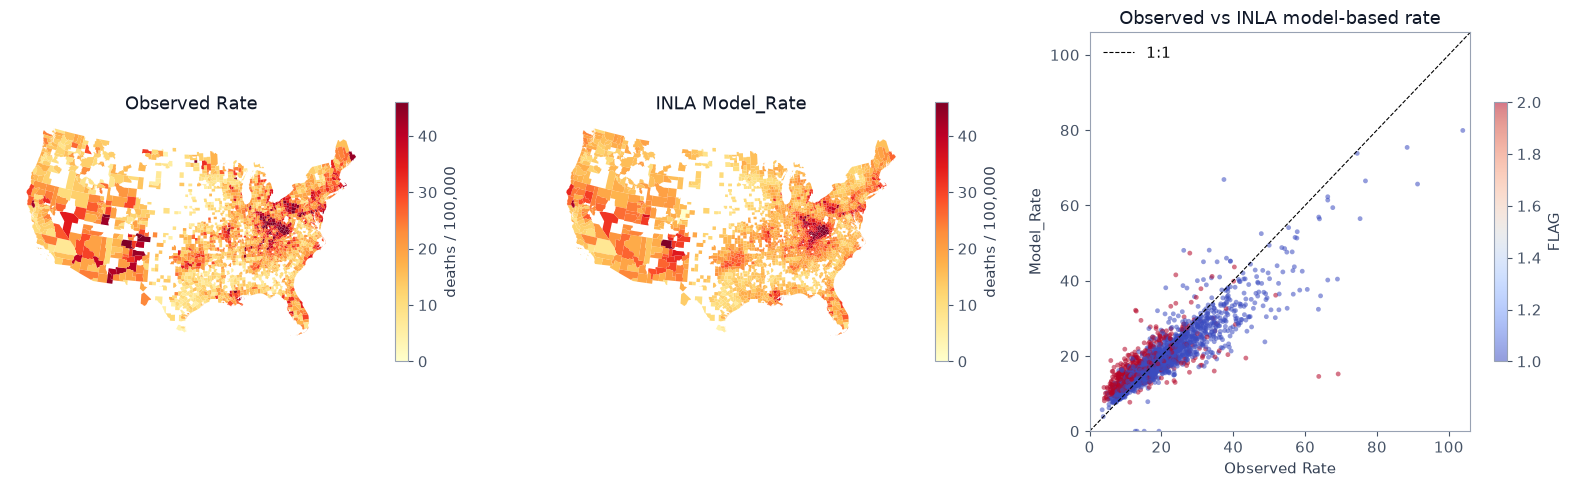

,n,rate_mean,model_mean,corr
FLAG,,,,
1,1621,21.526,20.079,0.909
2,529,15.132,17.304,0.664


,n,rate_mean,model_mean
URBAN_RURAL_ID,,,
1,68,19.47,20.46
2,350,20.88,18.94
3,625,19.35,18.72
4,1107,20.03,19.86


`FLAG = 1` counties (n = 1621) have higher mean observed rates and a tighter Rate–Model_Rate correlation than `FLAG = 2`. The INLA estimate is most useful where the raw rate is unstable; later models are scored on both surfaces.

In [3]:
vmax = float(np.nanpercentile(np.r_[counties["Rate"], counties["Model_Rate"]], 98))
fig, axes = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 1, 1.05]})

for ax, col, title in [
    (axes[0], "Rate", "Observed Rate"),
    (axes[1], "Model_Rate", "INLA Model_Rate"),
]:
    counties.plot(
        column=col, cmap="YlOrRd", vmin=0, vmax=vmax,
        legend=True, ax=ax, edgecolor="none",
        legend_kwds={"label": "deaths / 100,000", "shrink": 0.65},
    )
    ax.set_axis_off()
    ax.set_title(title)

# Scatter: observed vs model-based, coloured by FLAG.
sc = axes[2].scatter(
    counties["Rate"], counties["Model_Rate"],
    c=counties["FLAG"], cmap="coolwarm", s=12, alpha=0.55, linewidths=0,
)
lim = [0, max(counties["Rate"].max(), counties["Model_Rate"].max()) * 1.02]
axes[2].plot(lim, lim, "k--", lw=0.8, label="1:1")
axes[2].set_xlim(lim); axes[2].set_ylim(lim)
axes[2].set_xlabel("Observed Rate")
axes[2].set_ylabel("Model_Rate")
axes[2].set_title("Observed vs INLA model-based rate")
axes[2].legend(frameon=False, loc="upper left")
cbar = fig.colorbar(sc, ax=axes[2], shrink=0.65)
cbar.set_label("FLAG")
plt.tight_layout()
# ALT: Two CONUS county choropleths of overdose rates 2014-2018 (observed and INLA model-based) plus a scatter of the two coloured by FLAG.
plt.show()

flag_tbl = (
    counties.groupby("FLAG")
    .agg(n=("Rate", "size"), rate_mean=("Rate", "mean"), model_mean=("Model_Rate", "mean"),
         corr=("Rate", lambda s: s.corr(counties.loc[s.index, "Model_Rate"])))
    .round(3)
)
urban_tbl = (
    counties.groupby("URBAN_RURAL_ID")
    .agg(n=("Rate", "size"), rate_mean=("Rate", "mean"), model_mean=("Model_Rate", "mean"))
    .round(2)
)
display(flag_tbl)
display(urban_tbl)
display(Markdown(
    f"`FLAG = 1` counties (n = {int((counties.FLAG == 1).sum())}) have higher mean observed rates and a tighter "
    f"Rate–Model_Rate correlation than `FLAG = 2`. "
    f"The INLA estimate is most useful where the raw rate is unstable; later models are scored on both surfaces."
))

## Covariate structure

Correlation with each outcome, a pairwise heatmap among the modelling covariates, and variance-inflation factors on the standardised design matrix.

,with Rate,with Model_Rate
COPD,0.373,0.484
Insufficient_sleep,0.268,0.336
Smoking,0.267,0.364
POP_WHITE,0.232,0.255
POP_65,0.228,0.197
Unemployment,0.222,0.302
Uninsured_adults,-0.184,-0.127
POP_BLACK,-0.175,-0.166
Education,-0.156,-0.234
POP_HISPANIC,-0.154,-0.169


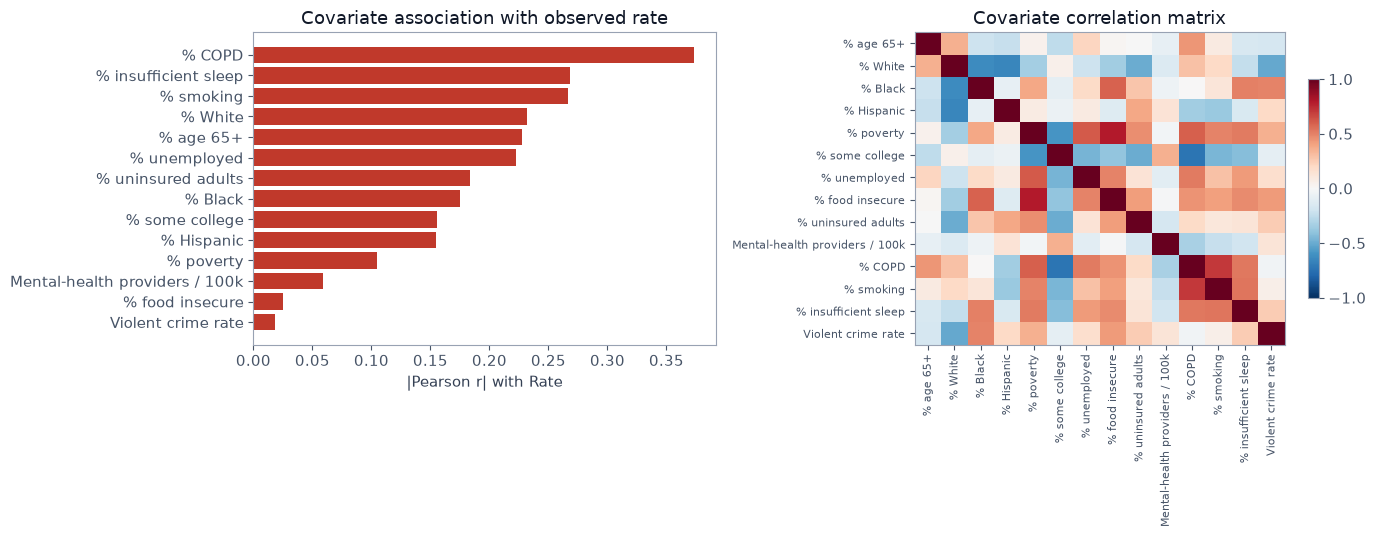

covariate,% age 65+,% White,% Black,% Hispanic,% poverty,% some college,% unemployed,% food insecure,% uninsured adults,Mental-health providers / 100k,% COPD,% smoking,% insufficient sleep,Violent crime rate
VIF,2.06,11.81,6.63,6.75,5.4,3.61,2.28,4.62,2.64,1.44,9.95,2.53,3.32,1.58


Largest |r| with `Rate` is **% COPD** (+0.373). Max VIF = **11.81** — elevated for % White (collinear with other race shares) and % COPD; we keep the full set for comparability across models, and interpret those two slopes cautiously.

In [4]:
corr_y = pd.DataFrame({
    "with Rate": counties[COVARS].corrwith(counties["Rate"]),
    "with Model_Rate": counties[COVARS].corrwith(counties["Model_Rate"]),
}).sort_values("with Rate", key=np.abs, ascending=False)
display(corr_y.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
# Ranked absolute correlations with Rate.
rank = corr_y["with Rate"].abs().sort_values()
axes[0].barh([COVAR_LABELS[c] for c in rank.index], rank.values, color=COLORS["red"])
axes[0].set_xlabel("|Pearson r| with Rate")
axes[0].set_title("Covariate association with observed rate")

R = counties[COVARS].corr()
im = axes[1].imshow(R, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
axes[1].set_xticks(range(len(COVARS)), [COVAR_LABELS[c] for c in COVARS], rotation=90, fontsize=8)
axes[1].set_yticks(range(len(COVARS)), [COVAR_LABELS[c] for c in COVARS], fontsize=8)
axes[1].set_title("Covariate correlation matrix")
fig.colorbar(im, ax=axes[1], shrink=0.7)
plt.tight_layout()
# ALT: Bar chart of absolute correlations with overdose Rate and a red-blue correlation heatmap among the fourteen covariates.
plt.show()

X_raw = counties[COVARS].to_numpy(dtype=float)
scaler = StandardScaler().fit(X_raw)
X = scaler.transform(X_raw)


def vif(Z):
    out = []
    for j in range(Z.shape[1]):
        others = np.column_stack([np.ones(len(Z)), np.delete(Z, j, axis=1)])
        beta, *_ = np.linalg.lstsq(others, Z[:, j], rcond=None)
        resid = Z[:, j] - others @ beta
        r2 = 1 - resid.var() / Z[:, j].var()
        out.append(1 / max(1 - r2, 1e-12))
    return np.asarray(out)


vif_tbl = pd.DataFrame({"covariate": [COVAR_LABELS[c] for c in COVARS], "VIF": vif(X)}).set_index("covariate")
display(vif_tbl.round(2).T)
display(Markdown(
    f"Largest |r| with `Rate` is **{COVAR_LABELS[corr_y.index[0]]}** ({corr_y.iloc[0]['with Rate']:+.3f}). "
    f"Max VIF = **{vif_tbl['VIF'].max():.2f}** — elevated for % White (collinear with other race shares) and % COPD; we keep the full set for comparability across models, and interpret those two slopes cautiously."
))

## Spatial autocorrelation of the outcomes

Before fitting local models, check that both rates are spatially clustered. Queen contiguity is the natural graph for county polygons; any island counties are linked to their nearest non-island neighbour.

Queen (raw)
Spatial Weights (W)
  Observations        2150
  Transform           row
  Min neighbors       0
  Mean neighbors      4.816
  Max neighbors       10
  Islands             30
  Components          47
  Nonzero weights     10354

Queen (islands linked)
Spatial Weights (W)
  Observations        2150
  Transform           row
  Min neighbors       1
  Mean neighbors      4.844
  Max neighbors       10
  Islands             0
  Components          17
  Nonzero weights     10414


,I,E[I],z,p_sim
"Observed overdose rate (per 100,000)",0.5697,-0.0005,38.2476,0.001
"INLA model-based overdose rate (per 100,000)",0.7400,-0.0005,49.6843,0.001


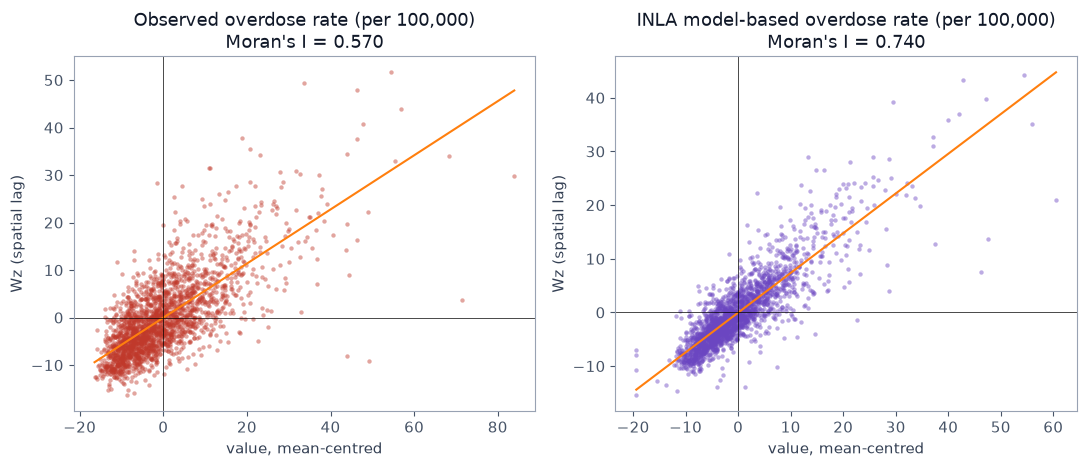

Raw Queen had **30** island(s); after linking, **0** remain in **17** component(s). Both surfaces are strongly clustered: Moran's I = **0.570** (`Rate`) and **0.740** (`Model_Rate`). Local models are justified; a single national slope is not enough.

In [5]:
from scipy.spatial import cKDTree


def attach_islands(w, xy):
    """Link each island to its nearest non-island county, both ways, then row-standardise."""
    ids = list(w.id_order)
    pos = {i: k for k, i in enumerate(ids)}
    islands = set(w.islands())
    neighbors = {i: list(w.neighbors[i]) for i in ids}
    if not islands:
        return W(neighbors, ids=ids, transform="row")
    tree = cKDTree(xy)
    for isl in islands:
        _, idxs = tree.query(xy[pos[isl]], k=min(25, len(ids)))
        for j in np.atleast_1d(idxs):
            other = ids[int(j)]
            if other == isl or other in islands:
                continue
            if other not in neighbors[isl]:
                neighbors[isl].append(other)
            if isl not in neighbors[other]:
                neighbors[other].append(isl)
            break
    return W(neighbors, ids=ids, transform="row")


w_raw = Queen(counties, transform="row")
w = attach_islands(w_raw, coords)
print("Queen (raw)")
print(w_raw.summary())
print("\nQueen (islands linked)")
print(w.summary())

morans = {
    o: Moran(counties[o].to_numpy(float), w, permutations=PERM, seed=SEED)
    for o in OUTCOMES
}
moran_tbl = pd.DataFrame({
    OUTCOMES[o]: {"I": m.I, "E[I]": m.get("expected_I"), "z": m.z_score, "p_sim": m.p_value}
    for o, m in morans.items()
}).T
display(moran_tbl.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, (o, m), color in zip(axes, morans.items(), [COLORS["red"], COLORS["purple"]]):
    moran_scatter(m, ax=ax, s=10, c=color, alpha=0.45, linewidths=0)
    ax.set_title(f"{OUTCOMES[o]}\nMoran's I = {m.I:.3f}")
    ax.set_xlabel("value, mean-centred")
plt.tight_layout()
# ALT: Moran scatterplots of observed and INLA model-based overdose rates under Queen contiguity on US county polygons.
plt.show()

display(Markdown(
    f"Raw Queen had **{len(w_raw.islands())}** island(s); after linking, **{len(w.islands())}** remain "
    f"in **{w.n_components()}** component(s). "
    f"Both surfaces are strongly clustered: Moran's I = **{morans['Rate'].I:.3f}** (`Rate`) and "
    f"**{morans['Model_Rate'].I:.3f}** (`Model_Rate`). Local models are justified; a single national slope is not enough."
))

## Global OLS baseline

A single national OLS for each outcome, for later comparison with local models. Coefficients are on the standardised covariates (pp of the rate per 1 SD).

In [6]:
y_vec = {o: counties[o].to_numpy(dtype=float) for o in OUTCOMES}
ols = {o: OLS(y_vec[o], X, w=w, y_name=o, names=COVARS) for o in OUTCOMES}

coef_ols = pd.DataFrame({OUTCOMES[o]: m.coef_frame().set_index("variable")["coef"] for o, m in ols.items()})
display(coef_ols.round(3))
display(Markdown(
    " | ".join(f"**{OUTCOMES[o]}**: R² = {ols[o].r2:.3f}, AIC = {ols[o].aic:.1f}" for o in OUTCOMES)
))

,"Observed overdose rate (per 100,000)","INLA model-based overdose rate (per 100,000)"
variable,,
const,19.952,19.396
POP_65,1.562,0.153
POP_WHITE,-0.993,1.682
POP_BLACK,-3.666,-1.683
POP_HISPANIC,-0.040,1.232
Poverty,-1.681,-0.743
Education,0.846,1.189
Unemployment,0.580,0.835
Food_insecurity,0.025,0.149


**Observed overdose rate (per 100,000)**: R² = 0.317, AIC = 15528.3 | **INLA model-based overdose rate (per 100,000)**: R² = 0.409, AIC = 13956.0

## Geographically weighted models

Four local models share the same adaptive bandwidth (\(k\) = 150 neighbours, bisquare kernel) and the same standardised covariates. Hyperparameters are kept modest so the notebook finishes in a reasonable time:

- **GWR** - local OLS at every county.
- **GWRandomForest** - global RF + local RFs (25 trees, depth 8), blended 50/50.
- **GWXGBoost** - global + local XGBoost (30 trees, depth 3).
- **GNNWR** - Spatially Weighted Neural Network that learns location weights, then local WLS (GPU if available).

In-sample \(R^2\) for tree ensembles is usually optimistic. Section 7 scores every model with spatial-block CV.

In [7]:
try:
    import torch
    NN_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except Exception:
    NN_DEVICE = "cpu"


def make_models():
    """Fresh model instances (fit mutates state)."""
    return {
        "GWR": GWR(
            bandwidth=BANDWIDTH, fixed=False, kernel="bisquare",
            criterion="AICc", hat_matrix=False, n_jobs=-1,
        ),
        "GW-RF": GWRandomForest(
            n_estimators=25, max_depth=8, bandwidth=BANDWIDTH, fixed=False,
            kernel="bisquare", local_weight=0.5, random_state=SEED, n_jobs=-1,
        ),
        "GW-XGBoost": GWXGBoost(
            n_estimators=30, max_depth=3, learning_rate=0.1,
            bandwidth=BANDWIDTH, fixed=False, kernel="bisquare",
            local_weight=0.5, n_jobs=-1,
        ),
        "GNNWR": GNNWR(
            hidden_layers=[64, 32], n_epochs=80, batch_size=128, patience=15,
            learning_rate=1e-3, device=NN_DEVICE, random_state=SEED,
        ),
    }


def r2_score(y_true, y_pred):
    y_true = np.asarray(y_true, float)
    y_pred = np.asarray(y_pred, float)
    return 1.0 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - y_true.mean()) ** 2)


def rmse(y_true, y_pred):
    return float(np.sqrt(np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2)))


def fitted_values(model, X_mat, y, coords_mat):
    """In-sample predictions: prefer model.fitted_ / residuals_, else predict()."""
    if getattr(model, "fitted_", None) is not None:
        return np.asarray(model.fitted_, float)
    if getattr(model, "residuals_", None) is not None:
        return y - np.asarray(model.residuals_, float)
    return np.asarray(model.predict(X_mat, coords_mat), float)


fits = {}          # fits[outcome][model_name] = dict(model, time, r2, rmse, pred)
print(f"GNNWR device: {NN_DEVICE}")
for outcome in OUTCOMES:
    fits[outcome] = {}
    y = y_vec[outcome]
    print(f"\n=== Fitting models for {outcome} ===")
    for name, model in make_models().items():
        t0 = time.time()
        model.fit(X, y, coords)
        elapsed = time.time() - t0
        pred = fitted_values(model, X, y, coords)
        fits[outcome][name] = {
            "model": model, "time": elapsed,
            "r2": r2_score(y, pred), "rmse": rmse(y, pred), "pred": pred,
        }
        print(f"  {name:10s}  {elapsed:6.1f}s   in-sample R² = {fits[outcome][name]['r2']:.3f}   RMSE = {fits[outcome][name]['rmse']:.2f}")

GNNWR device: cuda

=== Fitting models for Rate ===


  GWR           16.8s   in-sample R² = 0.709   RMSE = 5.80


  GW-RF         85.3s   in-sample R² = 0.888   RMSE = 3.61


  GW-XGBoost    22.0s   in-sample R² = 0.749   RMSE = 5.39


  GNNWR         64.2s   in-sample R² = 0.318   RMSE = 8.89

=== Fitting models for Model_Rate ===


  GWR           74.2s   in-sample R² = 0.805   RMSE = 3.54


  GW-RF         59.6s   in-sample R² = 0.912   RMSE = 2.38


  GW-XGBoost    45.4s   in-sample R² = 0.813   RMSE = 3.47


  GNNWR         16.0s   in-sample R² = 0.409   RMSE = 6.17


### In-sample comparison table

Useful for a first look — not the ranking to trust. Tree ensembles can nearly interpolate the training surface.

In [8]:
rows = []
for outcome in OUTCOMES:
    for name, d in fits[outcome].items():
        rows.append({
            "outcome": OUTCOMES[outcome], "model": name,
            "in_sample_R2": d["r2"], "in_sample_RMSE": d["rmse"], "fit_seconds": d["time"],
        })
in_sample = pd.DataFrame(rows)
display(in_sample.pivot(index="model", columns="outcome", values=["in_sample_R2", "in_sample_RMSE", "fit_seconds"]).round(3))

in_sample_R2  \
outcome    INLA model-based overdose rate (per 100,000)   
model                                                     
GNNWR                                             0.409   
GW-RF                                             0.912   
GW-XGBoost                                        0.813   
GWR                                               0.805   

                                                 \
outcome    Observed overdose rate (per 100,000)   
model                                             
GNNWR                                     0.318   
GW-RF                                     0.888   
GW-XGBoost                                0.749   
GWR                                       0.709   

                                         in_sample_RMSE  \
outcome    INLA model-based overdose rate (per 100,000)   
model                                                     
GNNWR                                             6.170   
GW-RF                                             2.378   
GW-XGBoost                                        3.468   
GWR                                               3.544   

                                                 \
outcome    Observed overdose rate (per 100,000)   
model                                             
GNNWR                                     8.893   
GW-RF                                     3.610   
GW-XGBoost                                5.393   
GWR                                       5.803   

                                            fit_seconds  \
outcome    INLA model-based overdose rate (per 100,000)   
model                                                     
GNNWR                                            16.004   
GW-RF                                            59.602   
GW-XGBoost                                       45.401   
GWR                                              74.194   

                                                 
outcome    Observed overdose rate (per 100,000)  
model                                            
GNNWR                                    64.211  
GW-RF                                    85.296  
GW-XGBoost                               22.043  
GWR                                      16.753

## Spatial-block cross-validation

Four geographic **quadrants** by median \(x\) and \(y\). Each fold trains on three quadrants and predicts the held-out quadrant. This is the fair comparison: neighbouring counties do not leak into the test fold the way they do under random \(k\)-fold CV.

In [9]:
mx, my = np.median(coords[:, 0]), np.median(coords[:, 1])
block = (coords[:, 0] > mx).astype(int) * 2 + (coords[:, 1] > my).astype(int)
print("block sizes:", {int(b): int((block == b).sum()) for b in np.unique(block)})


def spatial_cv(outcome, n_jobs_msg=True):
    """Return DataFrame of per-fold and mean R² / RMSE for each model."""
    y = y_vec[outcome]
    records = []
    for name, model0 in make_models().items():
        fold_r2, fold_rmse = [], []
        t0 = time.time()
        for b in sorted(np.unique(block)):
            test = np.where(block == b)[0]
            train = np.where(block != b)[0]
            # Rebuild a fresh model each fold.
            model = make_models()[name]
            model.fit(X[train], y[train], coords[train])
            pred = np.asarray(model.predict(X[test], coords[test]), float)
            fold_r2.append(r2_score(y[test], pred))
            fold_rmse.append(rmse(y[test], pred))
        records.append({
            "outcome": OUTCOMES[outcome], "model": name,
            "cv_R2_mean": float(np.mean(fold_r2)),
            "cv_R2_std": float(np.std(fold_r2)),
            "cv_RMSE_mean": float(np.mean(fold_rmse)),
            "fold_R2": np.round(fold_r2, 3).tolist(),
            "cv_seconds": time.time() - t0,
        })
        if n_jobs_msg:
            print(f"  {outcome:10s} {name:10s}  CV R² = {records[-1]['cv_R2_mean']:.3f} "
                  f"± {records[-1]['cv_R2_std']:.3f}   ({records[-1]['cv_seconds']:.0f}s)")
    return pd.DataFrame(records)


cv_frames = []
print("Spatial-block CV (4 quadrants)")
for outcome in OUTCOMES:
    cv_frames.append(spatial_cv(outcome))
cv = pd.concat(cv_frames, ignore_index=True)
display(cv[["outcome", "model", "cv_R2_mean", "cv_R2_std", "cv_RMSE_mean", "fold_R2", "cv_seconds"]].round(3))

block sizes: {0: 565, 1: 510, 2: 510, 3: 565}
Spatial-block CV (4 quadrants)


  Rate       GWR         CV R² = -0.978 ± 1.132   (24s)


/home/zia207/.pyenv/versions/3.11.16/lib/python3.11/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/zia207/.pyenv/versions/3.11.16/lib/python3.11/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/zia207/.pyenv/versions/3.11.16/lib/python3.11/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/zia207/.pyenv/versions/3.

/home/zia207/.pyenv/versions/3.11.16/lib/python3.11/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/zia207/.pyenv/versions/3.11.16/lib/python3.11/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/zia207/.pyenv/versions/3.11.16/lib/python3.11/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/zia207/.pyenv/versions/3.

/home/zia207/.pyenv/versions/3.11.16/lib/python3.11/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/zia207/.pyenv/versions/3.11.16/lib/python3.11/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/zia207/.pyenv/versions/3.11.16/lib/python3.11/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/zia207/.pyenv/versions/3.

/home/zia207/.pyenv/versions/3.11.16/lib/python3.11/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/zia207/.pyenv/versions/3.11.16/lib/python3.11/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/zia207/.pyenv/versions/3.11.16/lib/python3.11/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/zia207/.pyenv/versions/3.

... (73 outputs left out)

  Model_Rate GW-RF       CV R² = 0.152 ± 0.217   (275s)


  Model_Rate GW-XGBoost  CV R² = 0.189 ± 0.229   (133s)


  Model_Rate GNNWR       CV R² = 0.171 ± 0.189   (56s)


,outcome,model,cv_R2_mean,cv_R2_std,cv_RMSE_mean,fold_R2,cv_seconds
0,"Observed overdose rate (per 100,000)",GWR,-0.978,1.132,13.039,"[-0.003, -1.18, -2.748, 0.021]",24.021
1,"Observed overdose rate (per 100,000)",GW-RF,0.034,0.197,9.534,"[0.101, -0.277, 0.266, 0.047]",251.618
2,"Observed overdose rate (per 100,000)",GW-XGBoost,0.049,0.180,9.489,"[0.124, -0.226, 0.268, 0.029]",133.079
3,"Observed overdose rate (per 100,000)",GNNWR,0.053,0.175,9.482,"[-0.036, -0.107, 0.348, 0.008]",20.107
4,"INLA model-based overdose rate (per 100,000)",GWR,-0.722,0.668,9.573,"[-0.367, -0.688, -1.806, -0.025]",22.189
5,"INLA model-based overdose rate (per 100,000)",GW-RF,0.152,0.217,6.583,"[0.115, -0.127, 0.483, 0.138]",274.896
6,"INLA model-based overdose rate (per 100,000)",GW-XGBoost,0.189,0.229,6.417,"[0.163, -0.103, 0.539, 0.155]",133.069
7,"INLA model-based overdose rate (per 100,000)",GNNWR,0.171,0.189,6.528,"[0.048, -0.015, 0.477, 0.175]",56.391


### In-sample vs spatial CV

The gap between the two columns is the overfitting warning, especially for GW-RF. GWR can post a **negative** spatial-block CV R²: each local linear fit is tuned to its neighbourhood and transfers poorly to a far-away held-out quadrant. Ensemble and neural GW models degrade less under the same split because they keep a global component.

,outcome,model,in_sample_R2,in_sample_RMSE,fit_seconds,cv_R2_mean,cv_RMSE_mean,R2_gap
6,"INLA model-based overdose rate (per 100,000)",GW-XGBoost,0.813,3.468,45.401,0.189,6.417,0.625
7,"INLA model-based overdose rate (per 100,000)",GNNWR,0.409,6.170,16.004,0.171,6.528,0.238
5,"INLA model-based overdose rate (per 100,000)",GW-RF,0.912,2.378,59.602,0.152,6.583,0.760
4,"INLA model-based overdose rate (per 100,000)",GWR,0.805,3.544,74.194,-0.722,9.573,1.527
3,"Observed overdose rate (per 100,000)",GNNWR,0.318,8.893,64.211,0.053,9.482,0.264
2,"Observed overdose rate (per 100,000)",GW-XGBoost,0.749,5.393,22.043,0.049,9.489,0.700
1,"Observed overdose rate (per 100,000)",GW-RF,0.888,3.610,85.296,0.034,9.534,0.853
0,"Observed overdose rate (per 100,000)",GWR,0.709,5.803,16.753,-0.978,13.039,1.687


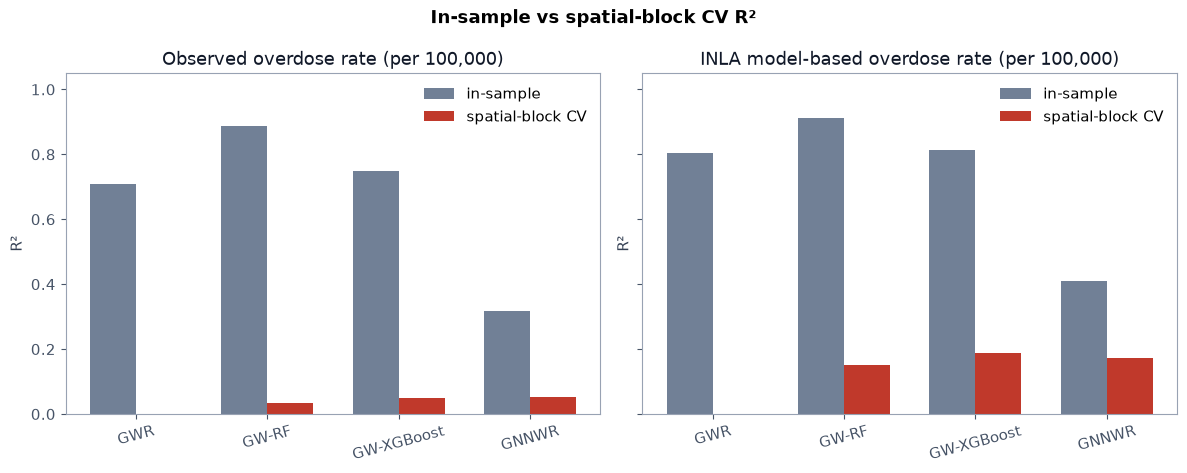

,model,cv_R2_mean,cv_RMSE_mean,in_sample_R2,R2_gap
outcome,,,,,
"INLA model-based overdose rate (per 100,000)",GW-XGBoost,0.189,6.417,0.813,0.625
"Observed overdose rate (per 100,000)",GNNWR,0.053,9.482,0.318,0.264


Best spatial-block CV model by outcome:

- **INLA model-based overdose rate (per 100,000)**: `GW-XGBoost` (CV R² = 0.189, in-sample = 0.813, gap = 0.625)
- **Observed overdose rate (per 100,000)**: `GNNWR` (CV R² = 0.053, in-sample = 0.318, gap = 0.264)

In [10]:
cmp = in_sample.merge(
    cv[["outcome", "model", "cv_R2_mean", "cv_RMSE_mean"]],
    on=["outcome", "model"],
)
cmp["R2_gap"] = cmp["in_sample_R2"] - cmp["cv_R2_mean"]
display(cmp.sort_values(["outcome", "cv_R2_mean"], ascending=[True, False]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
models_order = ["GWR", "GW-RF", "GW-XGBoost", "GNNWR"]
x = np.arange(len(models_order))
width = 0.35
for ax, outcome in zip(axes, OUTCOMES):
    sub = cmp[cmp["outcome"] == OUTCOMES[outcome]].set_index("model").loc[models_order]
    ax.bar(x - width / 2, sub["in_sample_R2"], width, label="in-sample", color=COLORS["grey"])
    ax.bar(x + width / 2, sub["cv_R2_mean"], width, label="spatial-block CV", color=COLORS["red"])
    ax.set_xticks(x, models_order, rotation=15)
    ax.set_ylabel("R²")
    ax.set_title(OUTCOMES[outcome])
    ax.set_ylim(0, 1.05)
    ax.legend(frameon=False, loc="upper right")
plt.suptitle("In-sample vs spatial-block CV R²", fontsize=13, fontweight="bold")
plt.tight_layout()
# ALT: Paired bars of in-sample and spatial-block CV R-squared for GWR, GW-RF, GW-XGBoost and GNNWR on Rate and Model_Rate.
plt.show()

best = (
    cmp.sort_values("cv_R2_mean", ascending=False)
    .groupby("outcome", sort=False)
    .first()[["model", "cv_R2_mean", "cv_RMSE_mean", "in_sample_R2", "R2_gap"]]
)
display(best.round(3))
display(Markdown(
    "Best spatial-block CV model by outcome:\n\n"
    + "\n".join(
        f"- **{out}**: `{row.model}` (CV R² = {row.cv_R2_mean:.3f}, "
        f"in-sample = {row.in_sample_R2:.3f}, gap = {row.R2_gap:.3f})"
        for out, row in best.iterrows()
    )
))

## Predictions and residuals on the map

Predicted surfaces and residuals for the **observed Rate**, for every model. Residuals that still show regional blobs mean the model missed a spatially structured factor.

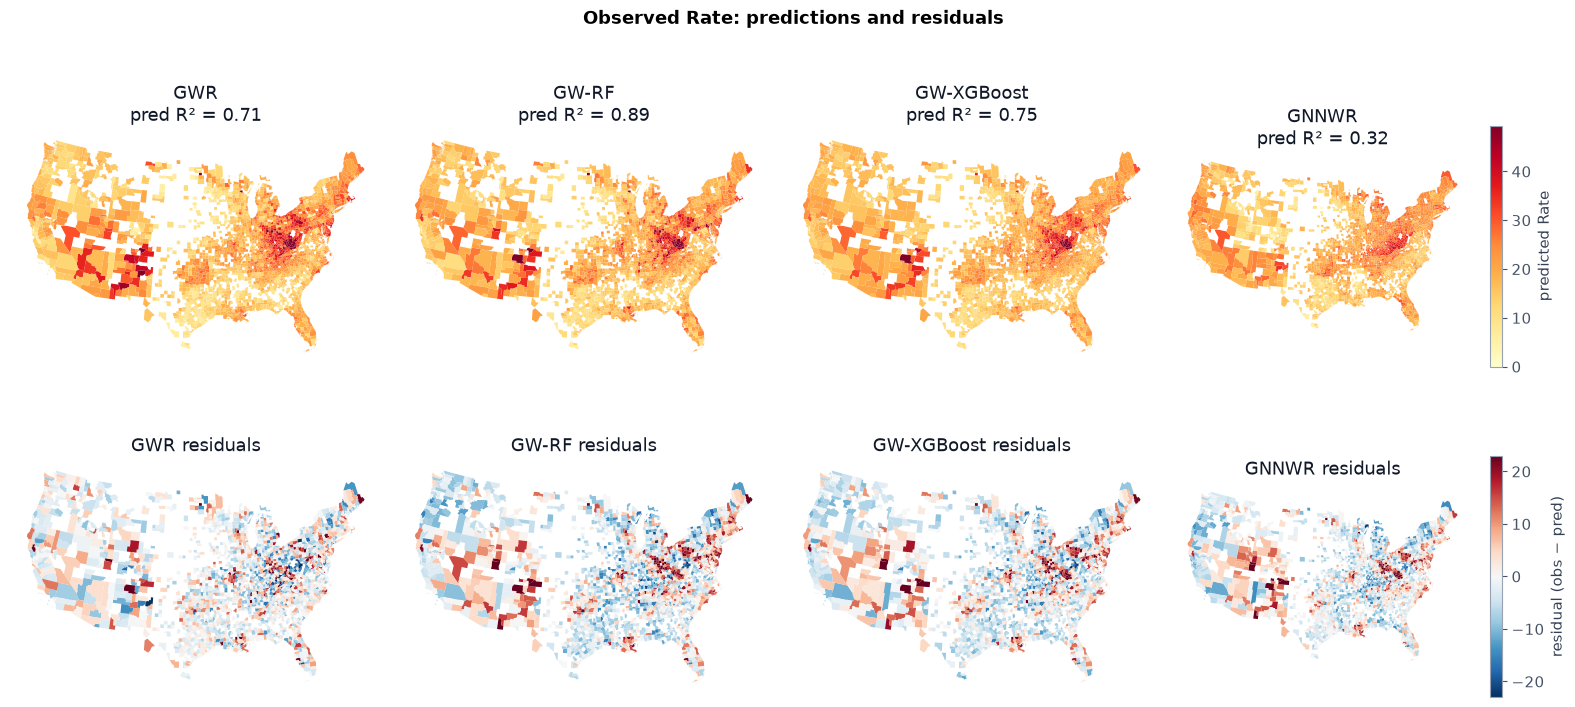

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
vmax_pred = float(np.nanpercentile(y_vec["Rate"], 98))
for j, name in enumerate(models_order):
    pred = fits["Rate"][name]["pred"]
    resid = y_vec["Rate"] - pred
    counties.assign(_p=pred).plot(
        column="_p", cmap="YlOrRd", vmin=0, vmax=vmax_pred,
        ax=axes[0, j], edgecolor="none", legend=(j == 3),
        legend_kwds={"label": "predicted Rate", "shrink": 0.6},
    )
    lim = float(np.nanpercentile(np.abs(resid), 98))
    counties.assign(_r=resid).plot(
        column="_r", cmap="RdBu_r",
        norm=TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim),
        ax=axes[1, j], edgecolor="none", legend=(j == 3),
        legend_kwds={"label": "residual (obs − pred)", "shrink": 0.6},
    )
    axes[0, j].set_title(f"{name}\npred R² = {fits['Rate'][name]['r2']:.2f}")
    axes[1, j].set_title(f"{name} residuals")
    axes[0, j].set_axis_off(); axes[1, j].set_axis_off()
plt.suptitle("Observed Rate: predictions and residuals", fontsize=13, fontweight="bold")
plt.tight_layout()
# ALT: Eight CONUS county choropleths — predicted overdose Rate and residuals for GWR, GW-RF, GW-XGBoost and GNNWR.
plt.show()

## Local structure: GWR slopes and GW-RF importances

GWR gives a local slope for every covariate. GW-RF gives a local feature-importance surface. Both answer *where* a relationship is strong, which a single CV score cannot.

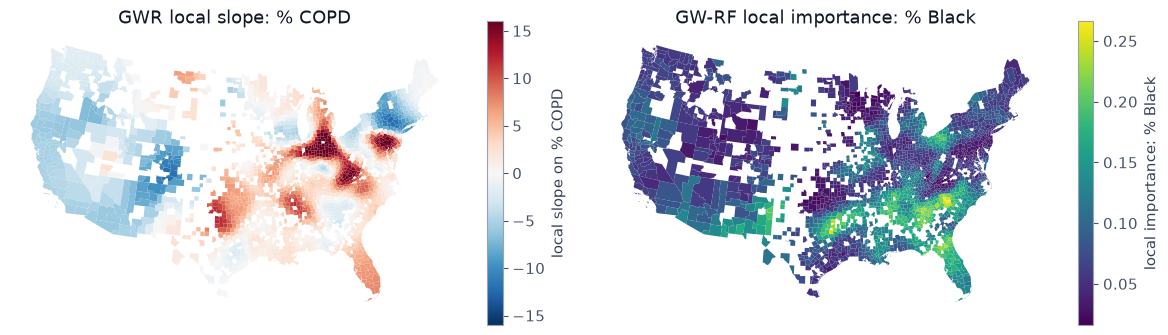

,mean local importance
POP_BLACK,0.0924
Unemployment,0.0865
COPD,0.0854
POP_WHITE,0.0845
POP_65,0.0807
POP_HISPANIC,0.0743
Smoking,0.0715
Poverty,0.0713
Violent_crime,0.0711
Food_insecurity,0.0651


GWR local slopes for **% COPD** run from **-12.47** to **23.90** (median 1.52). GW-RF ranks **% Black** highest on mean local importance (0.092).

In [12]:
gwr_rate = fits["Rate"]["GWR"]["model"]
gwrf_rate = fits["Rate"]["GW-RF"]["model"]

# GWR local coefficients (column 0 = intercept).
for j, col in enumerate(COVARS):
    counties[f"gwr_{col}"] = gwr_rate.coef_[:, 1 + j]

# Focus on the strongest global OLS correlate with Rate.
focus = corr_y.index[0]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
vals = counties[f"gwr_{focus}"]
lim = float(np.nanpercentile(np.abs(vals), 98))
counties.plot(
    column=f"gwr_{focus}", cmap="RdBu_r",
    norm=TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim),
    ax=axes[0], edgecolor="none", legend=True,
    legend_kwds={"label": f"local slope on {COVAR_LABELS[focus]}", "shrink": 0.65},
)
axes[0].set_axis_off()
axes[0].set_title(f"GWR local slope: {COVAR_LABELS[focus]}")

# GW-RF local importances.
if hasattr(gwrf_rate, "feature_importance_map"):
    imp = np.asarray(gwrf_rate.feature_importance_map(), float)
else:
    imp = np.asarray(gwrf_rate.feature_importances_local_, float)
imp_mean = pd.Series(imp.mean(axis=0), index=COVARS).sort_values(ascending=False)
top_imp = imp_mean.index[0]
counties.assign(_imp=imp[:, COVARS.index(top_imp)]).plot(
    column="_imp", cmap="viridis", ax=axes[1], edgecolor="none", legend=True,
    legend_kwds={"label": f"local importance: {COVAR_LABELS[top_imp]}", "shrink": 0.65},
)
axes[1].set_axis_off()
axes[1].set_title(f"GW-RF local importance: {COVAR_LABELS[top_imp]}")
plt.tight_layout()
# ALT: CONUS county choropleths of the GWR local slope for the top Rate covariate and the GW-RF local importance of its top feature.
plt.show()

display(imp_mean.rename("mean local importance").to_frame().round(4))
display(Markdown(
    f"GWR local slopes for **{COVAR_LABELS[focus]}** run from **{vals.min():.2f}** to **{vals.max():.2f}** "
    f"(median {np.median(vals):.2f}). "
    f"GW-RF ranks **{COVAR_LABELS[top_imp]}** highest on mean local importance "
    f"({imp_mean.iloc[0]:.3f})."
))

## Rate vs Model_Rate: does the target change the winner?

`Model_Rate` is already spatially smoothed. Models that themselves smooth can look better against it than against the raw rate. The table below repeats the CV ranking for both targets.

In [13]:
rank = (
    cmp.assign(rank=cmp.groupby("outcome")["cv_R2_mean"].rank(ascending=False))
    .sort_values(["outcome", "rank"])
)
display(rank[["outcome", "model", "rank", "cv_R2_mean", "cv_RMSE_mean", "in_sample_R2", "R2_gap"]].round(3))

# Agreement of predictions across targets for each model.
agree_rows = []
for name in models_order:
    p_rate = fits["Rate"][name]["pred"]
    p_model = fits["Model_Rate"][name]["pred"]
    agree_rows.append({
        "model": name,
        "corr(pred_Rate, pred_Model_Rate)": np.corrcoef(p_rate, p_model)[0, 1],
        "RMSE(pred_Rate, Rate)": rmse(y_vec["Rate"], p_rate),
        "RMSE(pred_Rate, Model_Rate)": rmse(y_vec["Model_Rate"], p_rate),
    })
display(pd.DataFrame(agree_rows).round(3))

,outcome,model,rank,cv_R2_mean,cv_RMSE_mean,in_sample_R2,R2_gap
6,"INLA model-based overdose rate (per 100,000)",GW-XGBoost,1.0,0.189,6.417,0.813,0.625
7,"INLA model-based overdose rate (per 100,000)",GNNWR,2.0,0.171,6.528,0.409,0.238
5,"INLA model-based overdose rate (per 100,000)",GW-RF,3.0,0.152,6.583,0.912,0.760
4,"INLA model-based overdose rate (per 100,000)",GWR,4.0,-0.722,9.573,0.805,1.527
3,"Observed overdose rate (per 100,000)",GNNWR,1.0,0.053,9.482,0.318,0.264
2,"Observed overdose rate (per 100,000)",GW-XGBoost,2.0,0.049,9.489,0.749,0.700
1,"Observed overdose rate (per 100,000)",GW-RF,3.0,0.034,9.534,0.888,0.853
0,"Observed overdose rate (per 100,000)",GWR,4.0,-0.978,13.039,0.709,1.687


,model,"corr(pred_Rate, pred_Model_Rate)","RMSE(pred_Rate, Rate)","RMSE(pred_Rate, Model_Rate)"
0,GWR,0.914,5.803,4.847
1,GW-RF,0.897,3.610,3.680
2,GW-XGBoost,0.915,5.393,3.819
3,GNNWR,0.959,8.893,6.469


## Decision log and summary

In [14]:
best_rate = best.loc[OUTCOMES["Rate"]]
best_modelrate = best.loc[OUTCOMES["Model_Rate"]]
decisions = pd.DataFrame([
    {"choice": "Data", "setting": f"{CSV.name} ⨝ US_COUNTY.shp", "reason": "Complete-case rates joined to county polygons on FIPS"},
    {"choice": "Outcomes", "setting": "Rate and Model_Rate", "reason": "Raw vs INLA-smoothed mortality rates"},
    {"choice": "Covariates", "setting": ", ".join(COVARS), "reason": "Demography, SES, access, chronic disease, behaviour"},
    {"choice": "CRS / coords", "setting": "EPSG:5070; polygon centroids", "reason": "US_COUNTY Conus Albers; centroids after join"},
    {"choice": "Weights (EDA)", "setting": "Queen, row-standardised, islands linked", "reason": "County polygon contiguity"},
    {"choice": "GW bandwidth", "setting": f"adaptive bisquare, k = {BANDWIDTH}", "reason": "Shared across GWR / GW-RF / GW-XGBoost"},
    {"choice": "GW-RF", "setting": "25 trees, max_depth 8, local_weight 0.5", "reason": "Capstone runtime vs accuracy"},
    {"choice": "GW-XGBoost", "setting": "30 trees, depth 3, lr 0.1, local_weight 0.5", "reason": "Matches Module 04_06 ensemble demo"},
    {"choice": "GNNWR", "setting": f"hidden [64,32], 80 epochs, device={NN_DEVICE}", "reason": "PyTorch SWNN + local WLS"},
    {"choice": "Validation", "setting": "4 geographic quadrant blocks", "reason": "Avoids neighbour leakage of random k-fold"},
    {"choice": "Best for Rate (CV)", "setting": str(best_rate["model"]),
     "reason": f"CV R² = {best_rate['cv_R2_mean']:.3f}"},
    {"choice": "Best for Model_Rate (CV)", "setting": str(best_modelrate["model"]),
     "reason": f"CV R² = {best_modelrate['cv_R2_mean']:.3f}"},
])
display(decisions)

r_rm = counties["Rate"].corr(counties["Model_Rate"])
nl = chr(10)
summary = (
    f"**Exploratory.** Across **{len(counties)}** counties, observed overdose `Rate` and INLA "
    f"`Model_Rate` correlate at **{r_rm:.3f}**. Both are strongly spatial (Moran's I "
    f"**{morans['Rate'].I:.3f}** and **{morans['Model_Rate'].I:.3f}**). The leading linear "
    f"correlate of `Rate` is **{COVAR_LABELS[focus]}**."
    + nl + nl +
    f"**Model comparison (spatial-block CV).** On the raw rate the best model is "
    f"**{best_rate['model']}** (CV R² = **{best_rate['cv_R2_mean']:.3f}**). On the model-based "
    f"rate the best model is **{best_modelrate['model']}** "
    f"(CV R² = **{best_modelrate['cv_R2_mean']:.3f}**). "
    f"GW-RF's in-sample R² is high but its CV gap is large — local forests can memorise the "
    f"training neighbourhood. GWR remains the most interpretable option when the scientific "
    f"question is a local slope, not a black-box prediction. GNNWR is included as the neural "
    f"geographically weighted alternative; its CV score should be read alongside the known "
    f"simplicity of the current SWNN training path in `geolattice`."
    + nl + nl +
    f"**Rate vs Model_Rate.** Scoring against `Model_Rate` rewards spatial smoothness. Prefer "
    f"`Rate` when the goal is to predict what a vital-statistics office publishes, and "
    f"`Model_Rate` when the goal is a precision-aware risk surface."
    + nl + nl +
    f"**Limits.** Ecological inference; 2014–2018 pooled cross-section; adaptive bandwidth "
    f"fixed a priori rather than AICc-tuned separately for every ensemble; GNNWR "
    f"early-stopping and architecture are not exhaustively tuned."
)
display(Markdown(summary))

,choice,setting,reason
0,Data,drug_overdose_all_2014_2018_updated_no_NA.csv ...,Complete-case rates joined to county polygons ...
1,Outcomes,Rate and Model_Rate,Raw vs INLA-smoothed mortality rates
2,Covariates,"POP_65, POP_WHITE, POP_BLACK, POP_HISPANIC, Po...","Demography, SES, access, chronic disease, beha..."
3,CRS / coords,EPSG:5070; polygon centroids,US_COUNTY Conus Albers; centroids after join
4,Weights (EDA),"Queen, row-standardised, islands linked",County polygon contiguity
5,GW bandwidth,"adaptive bisquare, k = 150",Shared across GWR / GW-RF / GW-XGBoost
6,GW-RF,"25 trees, max_depth 8, local_weight 0.5",Capstone runtime vs accuracy
7,GW-XGBoost,"30 trees, depth 3, lr 0.1, local_weight 0.5",Matches Module 04_06 ensemble demo
8,GNNWR,"hidden [64,32], 80 epochs, device=cuda",PyTorch SWNN + local WLS
9,Validation,4 geographic quadrant blocks,Avoids neighbour leakage of random k-fold


**Exploratory.** Across **2150** counties, observed overdose `Rate` and INLA `Model_Rate` correlate at **0.876**. Both are strongly spatial (Moran's I **0.570** and **0.740**). The leading linear correlate of `Rate` is **% COPD**.

**Model comparison (spatial-block CV).** On the raw rate the best model is **GNNWR** (CV R² = **0.053**). On the model-based rate the best model is **GW-XGBoost** (CV R² = **0.189**). GW-RF's in-sample R² is high but its CV gap is large — local forests can memorise the training neighbourhood. GWR remains the most interpretable option when the scientific question is a local slope, not a black-box prediction. GNNWR is included as the neural geographically weighted alternative; its CV score should be read alongside the known simplicity of the current SWNN training path in `geolattice`.

**Rate vs Model_Rate.** Scoring against `Model_Rate` rewards spatial smoothness. Prefer `Rate` when the goal is to predict what a vital-statistics office publishes, and `Model_Rate` when the goal is a precision-aware risk surface.

**Limits.** Ecological inference; 2014–2018 pooled cross-section; adaptive bandwidth fixed a priori rather than AICc-tuned separately for every ensemble; GNNWR early-stopping and architecture are not exhaustively tuned.

## Further reading

- Brunsdon, C., Fotheringham, A. S., & Charlton, M. (1996). Geographically weighted regression. *Geographical Analysis*.
- Fotheringham, A. S., Brunsdon, C., & Charlton, M. (2002). *Geographically Weighted Regression*.
- Georganos, S., et al. (2021). Geographical random forests. *Geocarto International*.
- Sun, K., & Hu, L. (2024). Theory-informed geographically weighted random forest (PyGRF).
- Du, Z., et al. Geographically neural network weighted regression (GNNWR).
- Rue, H., Martino, S., & Chopin, N. (2009). Approximate Bayesian inference for latent Gaussian models (INLA). *JRSS B*.
- Tobler, W. (1970). A computer movie simulating urban growth in the Detroit region. *Economic Geography*.

**Companion capstones:** [`04_10_01_health_disparities.ipynb`](04_10_01_health_disparities.ipynb), [`04_10_02_voting_pattern.ipynb`](04_10_02_voting_pattern.ipynb).

**Module tutorials:** [`04_06_09_ml_ensemble_models.ipynb`](../04_06_geographically_weighted_models/04_06_09_ml_ensemble_models.ipynb), [`04_06_11_deep_network_models.ipynb`](../04_06_geographically_weighted_models/04_06_11_deep_network_models.ipynb).